# Week 4: pandas for economic data

[Open in Colab](https://colab.research.google.com/github/WSU-EconS431/site/blob/main/weeks/week04.ipynb) · [View on GitHub](https://github.com/WSU-EconS431/site/blob/main/weeks/week04.ipynb)

So far the data in this course has been numbers we typed or drew at random. Real economic data arrives as tables: rows of countries, firms, or quarters, and columns of variables with units and gaps. **pandas** is the Python tool for tables. It selects rows by condition (like Week 3's Boolean masks), computes new columns, summarizes by group, and combines tables.

**After this week you can:**

- load a CSV file into a DataFrame and check its shape, types, units, and gaps before using it
- select columns and rows, including by condition, and sort
- create new columns and handle missing values without distorting an average
- summarize by group with `groupby` and combine two tables with `merge`, checking row counts
- reshape between long and wide tables and work with dates

All the data this week are real, from the course's `data` folder. [data/README.md](https://github.com/WSU-EconS431/site/blob/main/data/README.md) gives each source, the download date, and any changes.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path

# The course data live in the site repo's data folder. In Colab, read them from GitHub instead.
DATA = "../data" if Path("../data").exists() else "https://raw.githubusercontent.com/WSU-EconS431/site/main/data"

## 1. Series and DataFrames

A **DataFrame** is a table: named columns, one value per row in each. Each column is a **Series**, which is like a Week 3 array that also carries row labels (the **index**). We start with a made-up table of a market's prices and quantities by year.

In [2]:
market = pd.DataFrame({
    "year": [2019, 2020, 2021, 2022],
    "price": [28.0, 24.5, 31.0, 36.5],
    "quantity": [52, 61, 47, 40],
})
market

,year,price,quantity
0,2019,28.0,52
1,2020,24.5,61
2,2021,31.0,47
3,2022,36.5,40


Arithmetic on columns works on every row at once, as with arrays, and assigning to a new name creates a column:

In [3]:
market["revenue"] = market["price"] * market["quantity"]
print(market.shape, list(market.columns))
print("mean price:", market["price"].mean(), " highest revenue:", market["revenue"].max())
market

(4, 4) ['year', 'price', 'quantity', 'revenue']
mean price: 30.0  highest revenue: 1494.5


,year,price,quantity,revenue
0,2019,28.0,52,1456.0
1,2020,24.5,61,1494.5
2,2021,31.0,47,1457.0
3,2022,36.5,40,1460.0


Setting a column as the **index** lets you look rows up by label. `.loc[row label, column name]` is the label-based lookup:

In [4]:
by_year = market.set_index("year")
by_year.loc[2021, "price"]

np.float64(31.0)

## 2. Loading a real dataset

The **Maddison Project Database** (2020 release) estimates GDP per capita and population for 169 countries over a very long span. `gdppc` is GDP per capita in 2011 international dollars (adjusted so a dollar buys the same amount in every country), and `pop` is population in **thousands**. Check the units before computing anything.

In [5]:
mpd = pd.read_csv(f"{DATA}/mpd2020_full.csv")
mpd.head()

,countrycode,country,year,gdppc,pop
0,AFG,Afghanistan,1820,NaN,3280.0
1,AFG,Afghanistan,1870,NaN,4207.0
2,AFG,Afghanistan,1913,NaN,5730.0
3,AFG,Afghanistan,1950,1156.0,8150.0
4,AFG,Afghanistan,1951,1170.0,8284.0


In [6]:
print(mpd.shape)
mpd.info()

(21682, 5)
<class 'pandas.DataFrame'>
RangeIndex: 21682 entries, 0 to 21681
Data columns (total 5 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   countrycode  21682 non-null  str    
 1   country      21682 non-null  str    
 2   year         21682 non-null  int64  
 3   gdppc        19706 non-null  float64
 4   pop          17199 non-null  float64
dtypes: float64(2), int64(1), str(2)
memory usage: 847.1 KB


In [7]:
mpd.describe()

,year,gdppc,pop
count,21682.000000,19706.000000,1.719900e+04
mean,1880.124297,6693.285574,2.980356e+04
std,187.856176,10111.643395,9.842090e+04
min,1.000000,0.000000,2.000000e+00
25%,1861.000000,1553.000000,2.235000e+03
50%,1954.000000,2794.000000,5.830000e+03
75%,1986.000000,7099.541625,1.889884e+04
max,2018.000000,156299.000000,1.385439e+06


Look at the `min` of `gdppc`: it is 0.0, but no country has zero GDP per capita. Find those rows:

In [8]:
mpd[mpd['gdppc'] <= 0]

,countrycode,country,year,gdppc,pop
293,ARE,United Arab Emirates,1991,0.0,1934.841255
294,ARE,United Arab Emirates,1992,0.0,2050.441137


Two rows, the United Arab Emirates in 1991 and 1992, have a GDP per capita of zero and a population of about two million. That is almost certainly a placeholder for "no estimate", not a real zero, and it would break any calculation with logs (`np.log(0)` is $-\infty$). We treat these as missing in our working copy. The snapshot file stays exactly as downloaded, and the change is recorded here, in the notebook.

In [9]:
mpd.loc[mpd["gdppc"] <= 0, "gdppc"] = np.nan
print("smallest gdppc now:", mpd["gdppc"].min())

smallest gdppc now: 295.0


Three questions to ask of any new table, before any analysis:

1. **What is a row?** Here, one country in one year. The same country appears many times.
2. **What are the units?** Dollars per person, thousands of people.
3. **What is covered?** The `year` column starts at 1, and some countries start much later than others.

In [10]:
print("countries:", mpd["country"].nunique())
print("years:", mpd["year"].min(), "to", mpd["year"].max())
mpd[mpd["country"].str.startswith("Former")]["country"].unique()

countries: 169
years: 1 to 2018


<StringArray>
['Former USSR', 'Former Yugoslavia']
Length: 2, dtype: str

Look at that last result: some rows describe regions that no longer exist as countries (the "Former" rows), and the successor countries, such as the Russian Federation, appear as rows of their own. Adding up rows across countries would count that territory twice. Reading the data's documentation is part of the analysis.

## 3. Selecting columns and rows

One column in brackets gives a Series; a **list** of column names gives a DataFrame:

In [11]:
print(mpd["gdppc"].head(3))
mpd[["country", "year", "gdppc"]].head(3)

0   NaN
1   NaN
2   NaN
Name: gdppc, dtype: float64


,country,year,gdppc
0,Afghanistan,1820,NaN
1,Afghanistan,1870,NaN
2,Afghanistan,1913,NaN


A comparison gives a Boolean mask, exactly as in Week 3, and putting the mask inside the brackets keeps the rows where it is `True`. Combine conditions with `&` (and), `|` (or), and `~` (not), with **parentheses around each condition**:

In [12]:
usa = mpd[mpd["countrycode"] == "USA"]
japan_recent = mpd[(mpd["country"] == "Japan") & (mpd["year"] >= 2000)]
print(usa.shape, japan_recent.shape)
japan_recent.head(3)

(227, 5) (19, 5)


,countrycode,country,year,gdppc,pop
10626,JPN,Japan,2000,33210.8078,126933.1312
10627,JPN,Japan,2001,33246.3921,127234.3736
10628,JPN,Japan,2002,33195.4005,127502.5894


Python's `and` doesn't work here, for the same reason `if` didn't work on arrays in Week 3: a comparison on a column gives many `True`/`False` values, not one.

In [13]:
#| error: true
mpd[(mpd["country"] == "Japan") and (mpd["year"] >= 2000)]

ValueError: The truth value of a Series is ambiguous. Use a.empty, a.bool(), a.item(), a.any() or a.all().

`.query` writes the same filter as a string, and `.loc[rows, columns]` picks rows and columns together. `.sort_values` orders the rows; `.isin` tests membership in a list.

In [14]:
print(mpd.query("year == 2018 and gdppc > 60000")[["country", "gdppc"]])

y2018 = mpd[mpd["year"] == 2018]
rich = y2018.sort_values("gdppc", ascending=False)
print(rich[["country", "gdppc"]].head(5))
y2018.nsmallest(5, "gdppc")[["country", "gdppc"]]

                    country        gdppc
320    United Arab Emirates   76397.8181
2699            Switzerland   61372.7301
9228                Ireland   64684.3020
11106                Kuwait   65520.7367
14560                Norway   84580.1362
17166                 Qatar  153764.1643
17797             Singapore   68402.3451
                    country        gdppc
17166                 Qatar  153764.1643
14560                Norway   84580.1362
320    United Arab Emirates   76397.8181
17797             Singapore   68402.3451
11106                Kuwait   65520.7367


,country,gdppc
2336,Central African Republic,623.4889
1084,Burundi,651.3589
11319,Liberia,818.4211
3361,D.R. of the Congo,859.3817
13498,Niger,964.6601


In [15]:
big3 = mpd[mpd["country"].isin(["China", "India", "Japan"])]
big3["country"].value_counts()

country
China    243
Japan    212
India    208
Name: count, dtype: int64

## 4. New columns, units, and a gotcha

Total GDP is GDP per capita times population. Since `pop` is in thousands, $\text{gdppc} \times \text{pop}$ is in thousands of dollars, and dividing by $10^6$ gives **billions** of dollars. Writing the unit in a comment is a good habit.

In [16]:
mpd["gdp"] = mpd["gdppc"] * mpd["pop"] / 1e6        # billions of 2011 international dollars
mpd["log_gdppc"] = np.log(mpd["gdppc"])

y2018 = mpd[mpd["year"] == 2018]                      # re-select so it has the new columns
y2018.nlargest(5, "gdp")[["country", "gdppc", "pop", "gdp"]]

,country,gdppc,pop,gdp
3152,China,13101.7064,1.385439e+06,18151.620437
20752,United States,55334.7394,3.278347e+05,18140.645383
9026,India,6806.4986,1.298136e+06,8835.757695
18263,Former USSR,19539.1474,2.944740e+05,5753.769948
10644,Japan,38673.8081,1.258477e+05,4867.010473


China's total GDP just exceeds the United States' in 2018 on this measure, while its GDP per capita is about a quarter as large. Level and total are different questions.

**Gotcha: `mpd.pop` is not the `pop` column.** `pop` is also the name of a DataFrame *method*, so the dot shortcut `mpd.pop` gives you the method. Always use brackets for column names: `mpd["pop"]`. (`y2018` is a separate copy of the rows; changing it does not change `mpd`.)

In [17]:
type(mpd.pop), type(mpd['pop'])

(method, pandas.Series)

**Why logs?** The difference of logs, $\ln y_t - \ln y_{t-1}$, is approximately the growth rate of $y$ (a log difference of $0.02$ is about $2\%$ growth), and equal distances on a log scale are equal percentage changes. Economists use logs for GDP, prices, and populations constantly; Week 5 draws figures with them.

## 5. Missing data

Missing values are stored as `NaN` ("not a number"). Count them before deciding what to do:

In [18]:
print(mpd[["gdppc", "pop"]].isna().mean().round(3))     # share missing
modern = mpd[mpd["year"] >= 1950].copy()
coverage = modern.groupby("year")["gdppc"].count()      # count() counts non-missing values
print(coverage.loc[[1950, 1970, 1990, 2018]])

gdppc    0.091
pop      0.207
dtype: float64
year
1950    145
1970    153
1990    169
2018    169
Name: gdppc, dtype: int64


Before 1950 many countries have no estimate, and even since 1950 the number of countries with data changes from year to year (the *sample* changes, which matters when you compare a year-1950 average with a year-2018 average).

Most pandas summaries skip missing values by default. Filling them in is a different matter: **don't replace missing with 0**. A missing GDP is not a GDP of zero.

In [19]:
print("skip missing:", round(mpd["gdppc"].mean(), 1))
print("fillna(0):   ", round(mpd["gdppc"].fillna(0).mean(), 1))
print("keep complete rows only:", len(mpd.dropna(subset=["gdppc"])), "of", len(mpd))

skip missing: 6694.0
fillna(0):    6083.3
keep complete rows only: 19704 of 21682


## 6. Summaries by group: `groupby`

`groupby` splits the table into pieces (one per year, country, region), applies a summary to each, and combines the results. The median is often better than the mean for incomes, because a few very rich countries pull the mean up:

In [20]:
by_year = modern.groupby("year")["gdppc"].agg(["count", "median", "mean"])
by_year.loc[[1950, 1980, 2018]].round(0)

,count,median,mean
year,,,
1950,145,2174.0,3927.0
1980,167,6384.0,8616.0
2018,169,12310.0,19012.0


To compute growth *within each country*, sort by country and year and take a difference inside each group. `groupby(...).diff()` subtracts the previous row of the **same** country, so the first row of each country is missing:

In [21]:
modern = modern.sort_values(["countrycode", "year"])
modern["growth"] = modern.groupby("countrycode")["log_gdppc"].diff()        # log difference, about a growth rate
modern["decade"] = (modern["year"] // 10) * 10

(modern.groupby("decade")["growth"].median() * 100).round(2)                # median annual growth, percent

decade
1950    2.25
1960    2.97
1970    2.80
1980    1.06
1990    2.27
2000    3.54
2010    2.24
Name: growth, dtype: float64

The median country's growth was weakest in the 1980s and strongest in the 2000s. (The 1950s row covers only 1951–59, and the 2010s row only 2011–18. Check what `growth` means where a country has a gap in its years: the difference then spans more than one year. Here the years since 1950 are annual wherever they are present.)

## 7. Combining tables: `merge`

`country_groups.csv` is a small table that assigns 26 of the countries to a world region. To attach regions to the GDP data, **merge** the tables on their shared key, `countrycode`:

In [22]:
groups = pd.read_csv(f"{DATA}/country_groups.csv")
print(groups.head(3))

left = y2018.merge(groups, on="countrycode", how="left")      # keep every row of y2018
inner = y2018.merge(groups, on="countrycode", how="inner")    # keep only rows found in both
print(len(y2018), len(left), len(inner))
print("rows with no region in the left merge:", left["region"].isna().sum())

  countrycode             region
0         USA  Western Offshoots
1         CAN  Western Offshoots
2         AUS  Western Offshoots
169 169 26
rows with no region in the left merge: 143


`how="left"` keeps all the country rows and puts `NaN` where there's no match; `how="inner"` keeps only the matches. **After every merge, compare row counts** with what you expected. The most common merge bug is a key that is not unique in one of the tables, which silently multiplies rows. Adding `validate="many_to_one"` makes pandas check, and `indicator=True` records where each row came from.

In [23]:
check = mpd.merge(groups, on="countrycode", how="left", validate="many_to_one", indicator=True)
print(check["_merge"].value_counts())

dup = pd.concat([groups, groups.iloc[[0]]])      # the USA listed twice by mistake
print("extra rows from the duplicate key:", len(mpd.merge(dup, on="countrycode", how="left")) - len(mpd))

_merge
left_only     15032
both           6650
right_only        0
Name: count, dtype: int64


extra rows from the duplicate key: 227


In [24]:
#| error: true
mpd.merge(dup, on="countrycode", how="left", validate="many_to_one")

MergeError: Merge keys are not unique in right dataset; not a many-to-one merge

Duplicates in right:
 countrycode
        USA ...

In [25]:
inner.groupby("region")["gdppc"].median().sort_values().round(0)

region
Sub-Saharan Africa               5238.0
South and South East Asia        8139.0
Middle East and North Africa    15614.0
Latin America                   16494.0
Eastern Europe                  24669.0
East Asia                       37928.0
Western Europe                  38287.0
Western Offshoots               49831.0
Name: gdppc, dtype: float64

## 8. Long and wide tables

`mpd` is **long**: one row per country and year. For plotting several countries over time, or for subtracting one year from another, a **wide** table (one row per year, one column per country) is easier. `pivot` reshapes long to wide, and `melt` goes back.

In [26]:
wide = mpd.pivot(index="year", columns="country", values="gdppc")
wide.loc[[1950, 1990, 2018], ["China", "India", "Japan", "United States"]].round(0)

country,China,India,Japan,United States
year,,,,
1950,799.0,987.0,3062.0,15240.0
1990,2982.0,2087.0,29949.0,36982.0
2018,13102.0,6806.0,38674.0,55335.0


With a wide table, the average annual growth rate of every country from 1990 to 2018 is one line: $\bigl(\ln y_{2018} - \ln y_{1990}\bigr)/28$.

In [27]:
growth_90_18 = (np.log(wide.loc[2018]) - np.log(wide.loc[1990])) / (2018 - 1990)
print((growth_90_18.sort_values(ascending=False).head(5) * 100).round(2))
print("median country:", round(growth_90_18.median() * 100, 2), "% per year")

country
Qatar                9.20
Equatorial Guinea    8.73
Kuwait               6.80
Mongolia             6.58
Bahrain              6.42
dtype: float64
median country: 2.18 % per year


Several of the fastest growers are small, resource-rich economies; a high growth rate is not a recipe to copy. `melt` turns a wide table back into long form:

In [28]:
wide[["China", "India"]].loc[2016:].reset_index().melt(id_vars="year", var_name="country", value_name="gdppc")

,year,country,gdppc
0,2016,China,12569.0000
1,2017,China,12733.9314
2,2018,China,13101.7064
3,2016,India,6125.0000
4,2017,India,6449.1134
5,2018,India,6806.4986


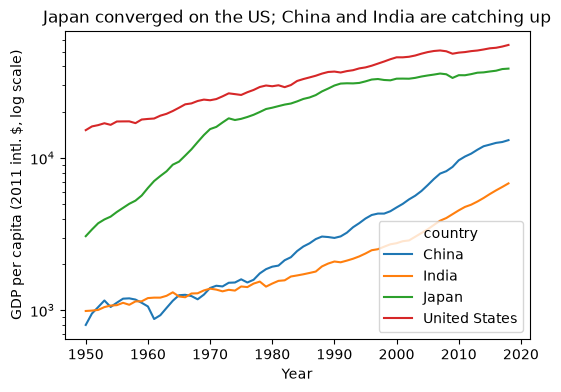

In [29]:
ax = wide.loc[1950:, ["China", "India", "Japan", "United States"]].plot(logy=True, figsize=(6, 4))
ax.set_xlabel("Year")
ax.set_ylabel("GDP per capita (2011 intl. $, log scale)")
ax.set_title("Japan converged on the US; China and India are catching up")
plt.show()

`DataFrame.plot` draws with Matplotlib and returns the same `ax` you used in Week 3, so the labeling steps are unchanged. Week 5 builds figures like this one with care.

## 9. Dates and time series

`us_macro_1959_2009.csv` has US quarterly data. Dates are the natural index for a time series. Here we build one from the year and quarter columns:

In [30]:
us = pd.read_csv(f"{DATA}/us_macro_1959_2009.csv")
us["date"] = pd.PeriodIndex.from_fields(year=us["year"], quarter=us["quarter"], freq="Q").to_timestamp()
us = us.set_index("date")
us[["realgdp", "unemp"]].head(3)

,realgdp,unemp
date,,
1959-01-01,2710.349,5.8
1959-04-01,2778.801,5.1
1959-07-01,2775.488,5.3


With a date index you can slice by period, compute changes over a number of quarters, take rolling averages, and aggregate to years:

In [31]:
us["gdp_growth"] = us["realgdp"].pct_change(4) * 100       # growth over the past 4 quarters (a year), percent
print(us.loc["2007":"2009", ["realgdp", "gdp_growth", "unemp"]].round(1))

print(us["unemp"].rolling(4).mean().tail(3).round(2))      # moving average of the last 4 quarters
us["realgdp"].resample("YE").mean().tail(3).round(0)       # average within each year

            realgdp  gdp_growth  unemp
date                                  
2007-01-01  13099.9         1.4    4.5
2007-04-01  13204.0         1.9    4.5
2007-07-01  13321.1         2.7    4.7
2007-10-01  13391.2         2.5    4.8
2008-01-01  13366.9         2.0    4.9
2008-04-01  13415.3         1.6    5.4
2008-07-01  13324.6         0.0    6.0
2008-10-01  13141.9        -1.9    6.9
2009-01-01  12925.4        -3.3    8.1
2009-04-01  12901.5        -3.8    9.2
2009-07-01  12990.3        -2.5    9.6
date
2009-01-01    6.60
2009-04-01    7.55
2009-07-01    8.45
Name: unemp, dtype: float64


date
2007-12-31    13254.0
2008-12-31    13312.0
2009-12-31    12939.0
Freq: YE-DEC, Name: realgdp, dtype: float64

## 10. Habits for working with data

- Look first: `shape`, `head`, `info`, `describe`. Check units and coverage.
- Name the unit in a comment or a column name (`gdp_billions`).
- After every merge, compare row counts, and use `validate=`.
- Don't fill missing values with 0, and say what you did with them.
- Re-run from the top (Restart and Run All) before you trust a result.

## 11. In-class lab

The exercises for this week are in **Lab 4**. It appears in the `lab04` folder of your repository at the start of the second class session (pull to see it), and you work on it in pairs.

## This week

- Read *Python Programming for Economics and Finance*: [17. Pandas](https://python-programming.quantecon.org/pandas.html).
- **PS04** (wrangling the Maddison data) is in the `ps04` folder of your repo.
- Week 5 turns these tables into figures.